In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as la
from scipy.interpolate import interp1d
import qutip as qt
import scqubits as scq


q1 = scq.TunableTransmon(EJmax=17.0, EC=0.2, d=0.0, ng=0.0, flux=0.0, ncut=15)
q2 = scq.Transmon(EJ=14.0, EC=0.2, ng=0.0, ncut=12)

spec1 = q1.eigenvals(evals_count=4)
w1_0 = float(spec1[1] - spec1[0])
alpha1_0 = float((spec1[2] - spec1[1]) - (spec1[1] - spec1[0]))
print(f"Q1 initial: w1={w1_0:.4f} GHz, alpha1={alpha1_0*1000:.1f} MHz")

spec2 = q2.eigenvals(evals_count=4)
w2 = float(spec2[1] - spec2[0])
alpha2 = float((spec2[2] - spec2[1]) - (spec2[1] - spec2[0]))

g_val = 0.01  # GHz
print(f"Q2: w2={w2:.4f} GHz, alpha2={alpha2*1000:.1f} MHz, g={g_val*1000:.1f} MHz")


# lookup tables for w1(phi), alpha1(phi)
flux_lookup = np.linspace(0.0, 0.4, 401)
w1_vals = []
alpha1_vals = []

for f in flux_lookup:
    q1.flux = float(f)
    spec = q1.eigenvals(evals_count=4)
    w1_vals.append(float(spec[1] - spec[0]))
    alpha1_vals.append(float((spec[2] - spec[1]) - (spec[1] - spec[0])))

w1_interp = interp1d(flux_lookup, w1_vals, kind="cubic", fill_value="extrapolate")
alpha1_interp = interp1d(flux_lookup, alpha1_vals, kind="cubic", fill_value="extrapolate")

Q1 initial: w1=5.0068 GHz, alpha1=-221.1 MHz
Q2: w2=4.5233 GHz, alpha2=-223.8 MHz, g=10.0 MHz


In [ ]:
# qutip operators
N = 4
a = qt.destroy(N)
I = qt.qeye(N)
I_full = qt.tensor(I, I)

a1_op = qt.tensor(a, I)
a2_op = qt.tensor(I, a)

n1_op = a1_op.dag() * a1_op
n2_op = a2_op.dag() * a2_op

kerr1_op = n1_op * (n1_op - I_full)
kerr2_op = n2_op * (n2_op - I_full)

H2_static   = 2*np.pi * (w2 * n2_op + 0.5 * alpha2 * kerr2_op)
Hint_static = 2*np.pi * (g_val * (a1_op.dag() * a2_op + a1_op * a2_op.dag()))

In [ ]:
# find flux of minimum |11>-|20> gap
dim = N * N
def idx(n1, n2): return n1*N + n2

ket_11_np = np.zeros(dim, dtype=complex); ket_11_np[idx(1,1)] = 1.0
ket_20_np = np.zeros(dim, dtype=complex); ket_20_np[idx(2,0)] = 1.0

def build_static_duffing_H(phi):
    w1 = float(w1_interp(float(phi)))
    a1 = float(alpha1_interp(float(phi)))
    H1 = 2*np.pi * (w1 * n1_op + 0.5 * a1 * kerr1_op)
    return H1 + H2_static + Hint_static

flux_scan = np.linspace(0.0, 0.40, 401)
gaps = []
for phi in flux_scan:
    H = build_static_duffing_H(phi).full()
    evals, evecs = la.eigh(H)
    o11 = np.abs(evecs.conj().T @ ket_11_np)**2
    o20 = np.abs(evecs.conj().T @ ket_20_np)**2
    i11 = int(np.argmax(o11)); i20 = int(np.argmax(o20))
    gaps.append(abs(evals[i20] - evals[i11]))

flux_cphase = float(flux_scan[int(np.argmin(gaps))])
print(f"CPHASE Flux: {flux_cphase:.4f}")

CPHASE Flux: 0.1420


In [ ]:
# compute E_11(phi), E_20(phi) for shoulder
def tracked_energies(phi):
    H = build_static_duffing_H(phi).full()
    evals, evecs = la.eigh(H)
    o11 = np.abs(evecs.conj().T @ ket_11_np)**2
    o20 = np.abs(evecs.conj().T @ ket_20_np)**2
    i11 = int(np.argmax(o11)); i20 = int(np.argmax(o20))
    return evals[i11], evals[i20]  # rad/ns

gap_min = float(np.min(gaps))
J = 0.5 * gap_min  # rad/ns

phi_test = flux_cphase + np.linspace(-0.08, 0, 401)

Delta = np.zeros_like(phi_test)

for i, ph in enumerate(phi_test):
    E11, E20 = tracked_energies(ph)
    Delta[i] = (E20 - E11)

P20_max_pred = 4*J**2 / (Delta**2 + 4*J**2)

target = 0.05
mask = P20_max_pred < target
if np.any(mask):
    idx_best = np.argmin(np.abs(phi_test[mask] - flux_cphase))
    phi_shoulder = float(phi_test[mask][idx_best])
    print(f"shoulder phi_hold = {phi_shoulder:.5f} (max P20 < {target})")
else:
    # fallback: pick the phi with the minimum predicted leakage
    idx_best = int(np.argmin(P20_max_pred))
    phi_shoulder = float(phi_test[idx_best])
    print(f"WARNING: no phi met target {target}. Using minimum leakage point: "
          f"phi_shoulder = {phi_shoulder:.5f}, predicted max P20 = {P20_max_pred[idx_best]:.4f}")

shoulder phi_hold = 0.10420 (max P20 < 0.05)


In [ ]:
E11, E20 = tracked_energies(phi_shoulder)
Delta_MHz = (E20 - E11) / (2*np.pi) * 1000
t_hold_estimate = np.pi * (E20 - E11) / (2 * (2*np.pi*g_val)**2) # ns
print(f"Detuning at shoulder: {Delta_MHz:.1f} MHz")
print(f"Estimated t_hold for pi phase: {t_hold_estimate:.0f} ns")
print(f"Estimated T_total: {t_hold_estimate + 2*60:.0f} ns")

Detuning at shoulder: 123.9 MHz
Estimated t_hold for pi phase: 310 ns
Estimated T_total: 430 ns


In [ ]:
def flux_pulse_array(tlist, phi_idle, phi_hold, t_rise, t_hold):
    tlist = np.asarray(tlist, dtype=float)
    phi_idle = float(phi_idle); phi_hold = float(phi_hold)
    t_rise = float(t_rise); t_hold = float(t_hold)

    phi = np.empty_like(tlist)

    t1 = t_rise
    t2 = t_rise + t_hold
    t3 = 2*t_rise + t_hold

    for i, t in enumerate(tlist):
        if t < 0:
            phi[i] = phi_idle
        elif t < t1:
            x = t / t_rise
            phi[i] = phi_idle + (phi_hold - phi_idle) * np.sin(np.pi*x/2)**2
        elif t < t2:
            phi[i] = phi_hold
        elif t < t3:
            x = (t - t2) / t_rise
            phi[i] = phi_hold - (phi_hold - phi_idle) * np.sin(np.pi*x/2)**2
        else:
            phi[i] = phi_idle
    return phi


def build_H_array(phi_idle, phi_hold, t_rise, t_hold, n_t=201):
    T_total = 2*float(t_rise) + float(t_hold)
    tlist = np.linspace(0.0, T_total, int(n_t))

    phi_t = flux_pulse_array(tlist, phi_idle, phi_hold, t_rise, t_hold)
    w1_t = 2*np.pi * w1_interp(phi_t)
    a1_t = 2*np.pi * 0.5 * alpha1_interp(phi_t)

    H = qt.QobjEvo(H2_static + Hint_static, tlist=tlist)
    H += qt.QobjEvo([n1_op, w1_t], tlist=tlist)
    H += qt.QobjEvo([kerr1_op, a1_t], tlist=tlist)

    return H, tlist, phi_t

In [ ]:
ket00 = qt.tensor(qt.basis(N,0), qt.basis(N,0))
ket01 = qt.tensor(qt.basis(N,0), qt.basis(N,1))
ket10 = qt.tensor(qt.basis(N,1), qt.basis(N,0))
ket11 = qt.tensor(qt.basis(N,1), qt.basis(N,1))
ket20 = qt.tensor(qt.basis(N,2), qt.basis(N,0))
ket02 = qt.tensor(qt.basis(N,0), qt.basis(N,2))

def wrap_pm_pi(x):
    return (x + np.pi) % (2*np.pi) - np.pi

def cz_phase_from_unitary(U):
    u00 = ket00.overlap(U * ket00)
    u01 = ket01.overlap(U * ket01)
    u10 = ket10.overlap(U * ket10)
    u11 = ket11.overlap(U * ket11)
    return wrap_pm_pi(np.angle(u11) - np.angle(u10) - np.angle(u01) + np.angle(u00))

args_base = {
    "phi_idle": 0.0,
    "phi_hold": phi_shoulder,
    "t_rise": 20.0,
    "t_hold": 30.0,
}

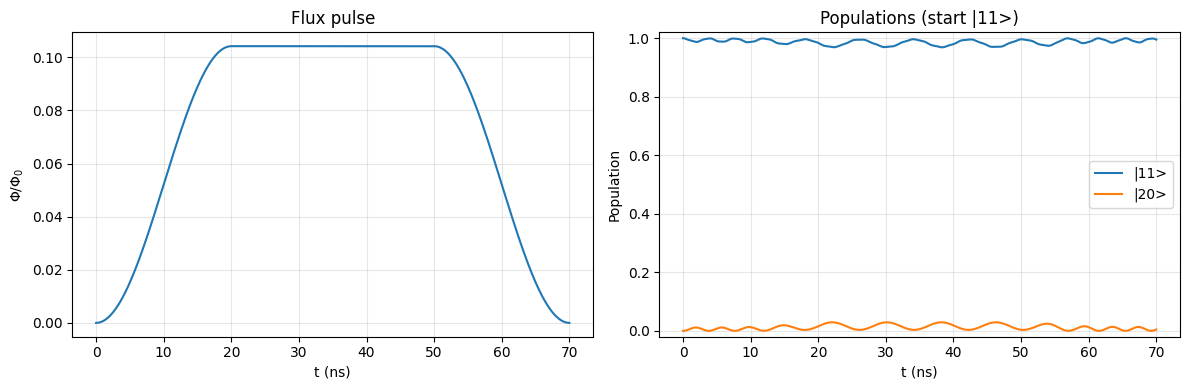

Final P11       = 0.995055
Max leakage P20 = 0.029263, final P20 = 4.639645e-03
Final CZ phase  = 23.9699 deg


In [ ]:
H0, tlist0, phi_wave0 = build_H_array(
    args_base["phi_idle"], args_base["phi_hold"],
    args_base["t_rise"], args_base["t_hold"],
    n_t=401
)

opts = {"nsteps": 100000, "rtol": 1e-6, "atol": 1e-8}

res11 = qt.sesolve(H0, ket11, tlist0, options=opts)

P11 = np.array([np.abs(ket11.overlap(st))**2 for st in res11.states])
P20 = np.array([np.abs(ket20.overlap(st))**2 for st in res11.states])

U0 = qt.propagator(H0, float(tlist0[-1]), options=opts)
cz0 = cz_phase_from_unitary(U0)

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(tlist0, phi_wave0)
axs[0].set_title("Flux pulse")
axs[0].set_xlabel("t (ns)")
axs[0].set_ylabel(r"$\Phi/\Phi_0$")
axs[0].grid(alpha=0.3)

axs[1].plot(tlist0, P11, label="|11>")
axs[1].plot(tlist0, P20, label="|20>")
axs[1].set_title("Populations (start |11>)")
axs[1].set_xlabel("t (ns)")
axs[1].set_ylabel("Population")
axs[1].set_ylim(-0.02, 1.02)
axs[1].grid(alpha=0.3)
axs[1].legend()

plt.tight_layout()
plt.show()

print(f"Final P11       = {P11[-1]:.6f}")
print(f"Max leakage P20 = {P20.max():.6f}, final P20 = {P20[-1]:.6e}")
print(f"Final CZ phase  = {np.degrees(cz0):.4f} deg")

In [ ]:
def wrap_pm_pi(x):
    return (x + np.pi) % (2*np.pi) - np.pi

def phase_err_to_pi(phi):
    err_rad = min(abs(wrap_pm_pi(phi - np.pi)), abs(wrap_pm_pi(phi + np.pi)))
    return np.degrees(err_rad)

def eval_gate_trotter(phi_hold, t_hold, *, n_t=2001):
    """
    Time-ordered propagation via midpoint matrix exponential.
    Returns: P11_final, P20_final, P20_max, cz_rad, phase_err_deg
    cz is in radians (used internally for phase math).
    phase_err is in degrees.
    """
    T_total = 2*float(args_base["t_rise"]) + float(t_hold)
    tlist = np.linspace(0.0, T_total, int(n_t))
    dt = float(tlist[1] - tlist[0])

    phi_t = flux_pulse_array(tlist, args_base["phi_idle"], float(phi_hold),
                             args_base["t_rise"], float(t_hold))

    w1_t = 2*np.pi * w1_interp(phi_t)
    a1_t = 2*np.pi * 0.5 * alpha1_interp(phi_t)

    H_static_np = (H2_static + Hint_static).full()
    n1 = n1_op.full()
    k1 = kerr1_op.full()

    v00 = ket00.full().ravel()
    v01 = ket01.full().ravel()
    v10 = ket10.full().ravel()
    v11 = ket11.full().ravel()

    v11_track = v11.copy()
    ket11_vec = ket11.full().ravel()
    ket20_vec = ket20.full().ravel()

    P20_max = 0.0

    for k in range(len(tlist) - 1):
        w_mid = 0.5 * (w1_t[k] + w1_t[k+1])
        a_mid = 0.5 * (a1_t[k] + a1_t[k+1])

        Hk = H_static_np + w_mid * n1 + a_mid * k1
        Uk = la.expm(-1j * Hk * dt)

        v00 = Uk @ v00
        v01 = Uk @ v01
        v10 = Uk @ v10
        v11 = Uk @ v11

        v11_track = Uk @ v11_track
        P20 = abs(np.vdot(ket20_vec, v11_track))**2
        if P20 > P20_max:
            P20_max = P20

    u00 = np.vdot(ket00.full().ravel(), v00)
    u01 = np.vdot(ket01.full().ravel(), v01)
    u10 = np.vdot(ket10.full().ravel(), v10)
    u11 = np.vdot(ket11.full().ravel(), v11)

    cz = wrap_pm_pi(np.angle(u11) - np.angle(u10) - np.angle(u01) + np.angle(u00))
    perr = phase_err_to_pi(cz)

    P11_final = abs(np.vdot(ket11_vec, v11_track))**2
    P20_final = abs(np.vdot(ket20_vec, v11_track))**2

    return float(P11_final), float(P20_final), float(P20_max), float(cz), float(perr)

phi_hold  = 0.10420
t_hold    = 369.492 ns
T_total   = 409.5 ns
final P11 = 0.991550
max P20   = 0.029266
CZ phase  = -179.4163 deg
phase err = 0.5837 deg


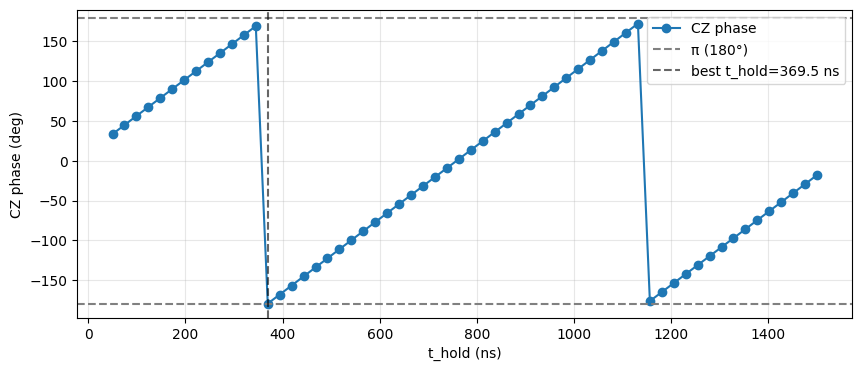

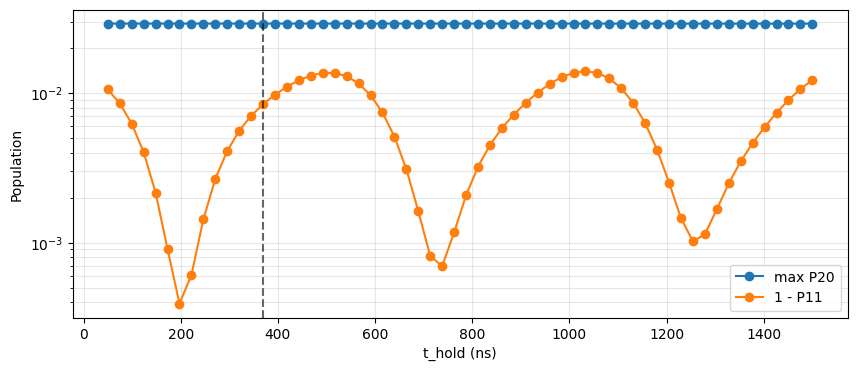

In [ ]:
phi_hold_use = float(phi_shoulder)

t_holds = np.linspace(50.0, 1500.0, 60)

P11f = []
P20m = []
czs  = []
perrs = []

n_t = 2001

for th in t_holds:
    P11, P20f, P20max, cz, perr = eval_gate_trotter(phi_hold_use, th, n_t=n_t)
    P11f.append(P11); P20m.append(P20max); czs.append(cz); perrs.append(perr)

P11f  = np.array(P11f)
P20m  = np.array(P20m)
czs   = np.array(czs)
perrs = np.array(perrs)

# perrs is in degrees. balance: 1 deg error ~ same weight as 1% leakage
score = perrs + 200*(1 - P11f) + 500*P20m
j = int(np.argmin(score))

print(f"phi_hold  = {phi_hold_use:.5f}")
print(f"t_hold    = {t_holds[j]:.3f} ns")
print(f"T_total   = {2*args_base['t_rise'] + t_holds[j]:.1f} ns")
print(f"final P11 = {P11f[j]:.6f}")
print(f"max P20   = {P20m[j]:.6f}")
print(f"CZ phase  = {np.degrees(czs[j]):.4f} deg")
print(f"phase err = {perrs[j]:.4f} deg")

plt.figure(figsize=(10, 4))
plt.plot(t_holds, np.degrees(czs), "o-", label="CZ phase")
plt.axhline(180.0,  ls="--", color="gray", label="π (180°)")
plt.axhline(-180.0, ls="--", color="gray")
plt.axvline(t_holds[j], ls="--", color="k", alpha=0.6,
            label=f"best t_hold={t_holds[j]:.1f} ns")
plt.xlabel("t_hold (ns)")
plt.ylabel("CZ phase (deg)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.semilogy(t_holds, P20m,   "o-", label="max P20")
plt.semilogy(t_holds, 1-P11f, "o-", label="1 - P11")
plt.axvline(t_holds[j], ls="--", color="k", alpha=0.6)
plt.xlabel("t_hold (ns)")
plt.ylabel("Population")
plt.grid(alpha=0.3, which="both")
plt.legend()
plt.show()

Final parameters:
  phi_hold = 0.11087
  t_hold   = 260.492 ns
  t_rise   = 60.0 ns
  T_total  = 380.5 ns

Final P11       = 0.999294
Max P20         = 0.035372
Final P20       = 5.339721e-04
CZ phase        = -179.9623 deg
Phase error     = 0.0377 deg


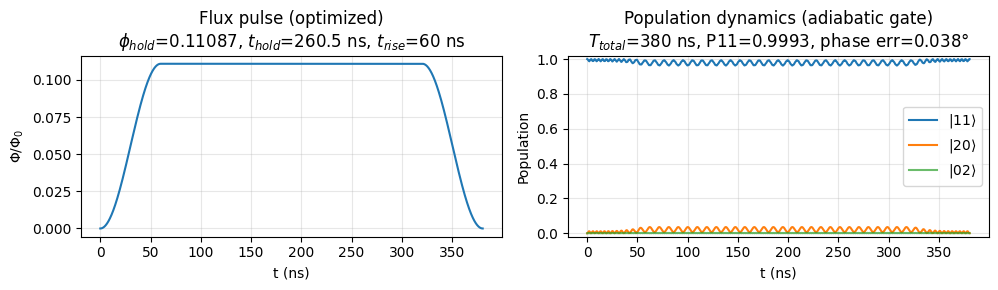

In [ ]:
# Post-optimization: flux pulse + population dynamics for best refined point
# Select the best point manually from refinement output above
# Using: phi=0.11087, t_hold=260.492 ns (from "Fastest refined with maxP20<=0.05")

phi_best_adiab = 0.11087
t_hold_best_adiab = 260.492

args_base["t_rise"] = 60.0
args_base["phi_hold"] = phi_best_adiab

T_total_adiab = 2*args_base["t_rise"] + t_hold_best_adiab
print(f"Final parameters:")
print(f"  phi_hold = {phi_best_adiab:.5f}")
print(f"  t_hold   = {t_hold_best_adiab:.3f} ns")
print(f"  t_rise   = {args_base['t_rise']:.1f} ns")
print(f"  T_total  = {T_total_adiab:.1f} ns")

H_best, tlist_best, phi_wave_best = build_H_array(
    args_base["phi_idle"], phi_best_adiab,
    args_base["t_rise"], t_hold_best_adiab,
    n_t=2001
)

opts_final = {"nsteps": 800000, "rtol": 1e-8, "atol": 1e-10}

res11_best = qt.sesolve(H_best, ket11, tlist_best, options=opts_final)

P11_best = np.array([np.abs(ket11.overlap(st))**2 for st in res11_best.states])
P20_best = np.array([np.abs(ket20.overlap(st))**2 for st in res11_best.states])
P02_best = np.array([np.abs(ket02.overlap(st))**2 for st in res11_best.states])

U_best = qt.propagator(H_best, float(tlist_best[-1]), options=opts_final)
cz_best_val = cz_phase_from_unitary(U_best)

print(f"\nFinal P11       = {P11_best[-1]:.6f}")
print(f"Max P20         = {P20_best.max():.6f}")
print(f"Final P20       = {P20_best[-1]:.6e}")
print(f"CZ phase        = {np.degrees(cz_best_val):.4f} deg")
print(f"Phase error     = {abs(180.0 - abs(np.degrees(cz_best_val))):.4f} deg")

fig, axs = plt.subplots(1, 2, figsize=(10, 3))

axs[0].plot(tlist_best, phi_wave_best)
axs[0].set_title(f"Flux pulse (optimized)\n"
                 f"$\\phi_{{hold}}$={phi_best_adiab:.5f}, "
                 f"$t_{{hold}}$={t_hold_best_adiab:.1f} ns, "
                 f"$t_{{rise}}$={args_base['t_rise']:.0f} ns")
axs[0].set_xlabel("t (ns)")
axs[0].set_ylabel(r"$\Phi/\Phi_0$")
axs[0].grid(alpha=0.3)

axs[1].plot(tlist_best, P11_best, label=r"$|11\rangle$")
axs[1].plot(tlist_best, P20_best, label=r"$|20\rangle$")
axs[1].plot(tlist_best, P02_best, label=r"$|02\rangle$", alpha=0.7)
axs[1].set_title(f"Population dynamics (adiabatic gate)\n"
                 f"$T_{{total}}$={T_total_adiab:.0f} ns, "
                 f"P11={P11_best[-1]:.4f}, "
                 f"phase err={abs(180.0 - abs(np.degrees(cz_best_val))):.3f}°")
axs[1].set_xlabel("t (ns)")
axs[1].set_ylabel("Population")
axs[1].set_ylim(-0.02, 1.02)
axs[1].grid(alpha=0.3)
axs[1].legend()

plt.tight_layout()
plt.show()

 /usr/local/lib/python3.13/dist-packages/qutip/core/coefficient.py: 199

|00> done
|01> done
|10> done
|11> done

Diagonal phases: [  0.          -2.01067487 167.82410537 -14.14955105]

Average gate fidelity CZ: 99.9321%  (infidelity 0.0679%)
|01>->|10> transfer: 0.1696%
|10>->|01> transfer: 0.1696%


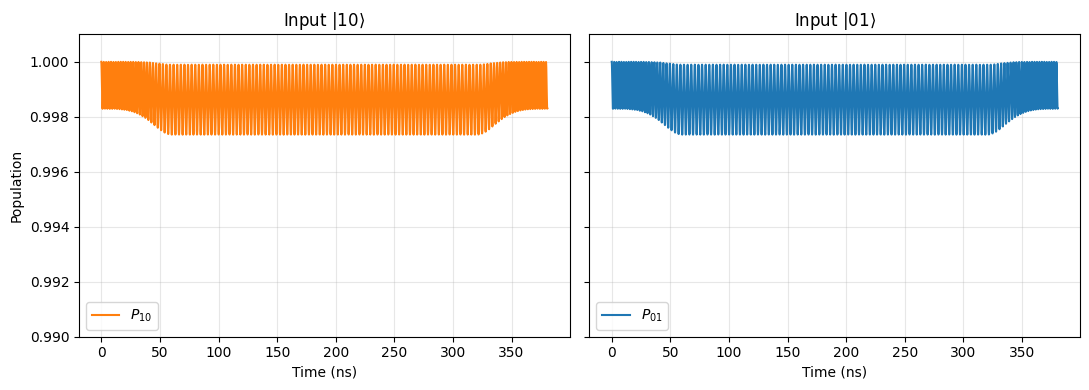

In [ ]:
# ── rebuild H_t and tlist from final adiabatic parameters ──────────────
from scipy.interpolate import interp1d as _i1d

phi_final  = 0.11087
t_hold_fin = 260.492
t_rise_fin = 60.0
T_total    = 380.5

# sin² ramp waveform
def phi_adiabatic(t):
    if t < t_rise_fin:
        return phi_final * np.sin(np.pi * t / (2 * t_rise_fin))**2
    elif t < t_rise_fin + t_hold_fin:
        return phi_final
    else:
        return phi_final * (1 - np.sin(np.pi * (t - t_rise_fin - t_hold_fin) / (2 * t_rise_fin))**2)

n_t   = 4000
tlist = np.linspace(0, T_total, n_t)

def _w1(t, args=None):
    return 2*np.pi * float(w1_interp(abs(phi_adiabatic(t))))
def _a1(t, args=None):
    return 2*np.pi * 0.5 * float(alpha1_interp(abs(phi_adiabatic(t))))

H_t = [H2_static + Hint_static,
       [n1_op, _w1],
       [kerr1_op, _a1]]

solve_opts = {"rtol": 1e-8, "atol": 1e-10, "nsteps": 200000, "max_step": 0.2}

# ── basis state kets ────────────────────────────────────────────────────
dim = N * N
def _idx(n1, n2): return n1*N + n2
dims_ket = [[N, N], [1, 1]]

def make_ket(n1, n2):
    v = np.zeros(dim, dtype=complex)
    v[_idx(n1, n2)] = 1.0
    return qt.Qobj(v, dims=dims_ket)

ket00 = make_ket(0,0); ket01 = make_ket(0,1)
ket10 = make_ket(1,0); ket11 = make_ket(1,1)

# ── fidelity from all four basis states ─────────────────────────────────
results = {}
for label, ket in [('00',ket00),('01',ket01),('10',ket10),('11',ket11)]:
    results[label] = qt.sesolve(H_t, ket, tlist, options=solve_opts)
    print(f"|{label}> done")

# build U_CZ matrix (computational subspace)
U_CZ = np.zeros((4,4), dtype=complex)
for j, (label, ket) in enumerate([('00',ket00),('01',ket01),('10',ket10),('11',ket11)]):
    psi_f = results[label].states[-1]
    for i, bra in enumerate([ket00,ket01,ket10,ket11]):
        U_CZ[i,j] = complex(bra.dag() * psi_f)

# virtual-Z: remove single-qubit phases
phi_00 = np.angle(U_CZ[0,0])
phi_01 = np.angle(U_CZ[1,1])
phi_10 = np.angle(U_CZ[2,2])
phi_11 = np.angle(U_CZ[3,3])
print(f"\nDiagonal phases: {np.degrees([phi_00,phi_01,phi_10,phi_11])}")

# correct single-qubit phases
th1 = phi_10 - phi_00
th2 = phi_01 - phi_00
Z1 = np.diag([1, 1, np.exp(-1j*th1), np.exp(-1j*th1)])
Z2 = np.diag([1, np.exp(-1j*th2), 1, np.exp(-1j*th2)])

def closest_unitary(M):
    U, s, Vh = np.linalg.svd(M)
    return U @ Vh
U_can = closest_unitary(Z1 @ Z2 @ U_CZ)

# average gate fidelity (Pedersen formula, unitary case)
d = 4
M = np.array([[1,0,0,0],[0,1,0,0],[0,0,1,0],[0,0,0,-1]], dtype=complex) @ U_can.conj().T
F_avg = (d + abs(np.trace(M))**2) / (d*(d+1))
print(f"\nAverage gate fidelity CZ: {F_avg*100:.4f}%  (infidelity {(1-F_avg)*100:.4f}%)")

# exchange error
eps_01_10 = float(abs(U_CZ[2,1])**2)
eps_10_01 = float(abs(U_CZ[1,2])**2)
print(f"|01>->|10> transfer: {eps_01_10*100:.4f}%")
print(f"|10>->|01> transfer: {eps_10_01*100:.4f}%")

# ── exchange oscillation plot ────────────────────────────────────────────
result01 = qt.sesolve(H_t, ket01, tlist, options=solve_opts)
result10 = qt.sesolve(H_t, ket10, tlist, options=solve_opts)

P10_from10 = [float(abs(complex(ket10.dag()*s))**2) for s in result10.states]
P01_from01 = [float(abs(complex(ket01.dag()*s))**2) for s in result01.states]

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
axes[0].plot(tlist, P10_from10, color='C1', label=r'$P_{10}$')
axes[0].set_ylim(0.990, 1.001)
axes[0].set_title(r'Input $|10\rangle$')
axes[0].set_xlabel('Time (ns)'); axes[0].set_ylabel('Population')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(tlist, P01_from01, color='C0', label=r'$P_{01}$')
axes[1].set_ylim(0.990, 1.001)
axes[1].set_title(r'Input $|01\rangle$')
axes[1].set_xlabel('Time (ns)')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
#plt.savefig('fig_adiabatic_exchange.png', dpi=150)
plt.show()

 <>: 88SyntaxWarning: invalid escape sequence '\p'
 <>: 88SyntaxWarning: invalid escape sequence '\p'
 /tmp/ipykernel_888/2003564475.py: 88

computing adiabatic chevrons (this takes a few minutes):
  row 1/101
  row 6/101
  row 11/101
  row 16/101
  row 21/101
  row 26/101
  row 31/101
  row 36/101
  row 41/101
  row 46/101
  row 51/101
  row 56/101
  row 61/101
  row 66/101
  row 71/101
  row 76/101
  row 81/101
  row 86/101
  row 91/101
  row 96/101
  row 101/101


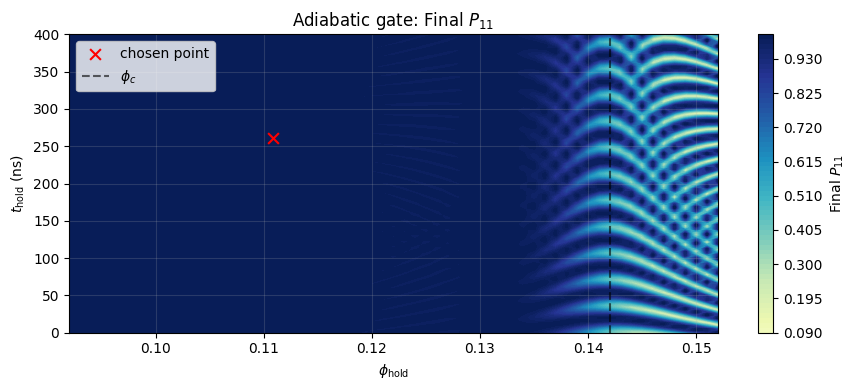

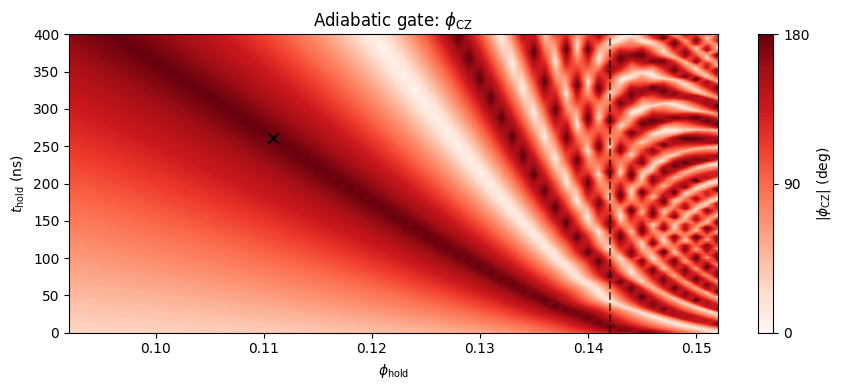

In [ ]:
# ── fast chevron for adiabatic gate ─────────────────────────────────────
from scipy.linalg import expm as la_expm

Hconst_np = (H2_static + Hint_static).full()
n1_np     = n1_op.full()
kerr1_np  = kerr1_op.full()

def wrap_deg_signed(x):
    return (x + 180.0) % 360.0 - 180.0

def adiabatic_chevron_point(phi_hold, t_hold, t_rise=60.0, DT=1.0):
    T_tot = 2*t_rise + t_hold
    nsteps = int(np.ceil(T_tot / DT))
    tcoarse = np.linspace(0, T_tot, nsteps+1)
    dt = tcoarse[1] - tcoarse[0]

    def phi_t(t):
        if t < t_rise:
            return phi_hold * np.sin(np.pi*t/(2*t_rise))**2
        elif t < t_rise + t_hold:
            return phi_hold
        else:
            return phi_hold*(1 - np.sin(np.pi*(t-t_rise-t_hold)/(2*t_rise))**2)

    phi_coarse = np.array([phi_t(t) for t in tcoarse])
    w1_t  = 2*np.pi * np.array([float(w1_interp(p)) for p in phi_coarse])
    a1h_t = 2*np.pi * 0.5 * np.array([float(alpha1_interp(p)) for p in phi_coarse])

    Psi = np.column_stack([
        ket00.full().ravel(), ket01.full().ravel(),
        ket10.full().ravel(), ket11.full().ravel()
    ])

    for k in range(nsteps):
        w_mid = 0.5*(w1_t[k] + w1_t[k+1])
        a_mid = 0.5*(a1h_t[k] + a1h_t[k+1])
        Hmid  = Hconst_np + w_mid*n1_np + a_mid*kerr1_np
        U     = la_expm(-1j * Hmid * dt)
        Psi   = U @ Psi

    u00 = ket00.full().ravel().conj() @ Psi[:,0]
    u01 = ket01.full().ravel().conj() @ Psi[:,1]
    u10 = ket10.full().ravel().conj() @ Psi[:,2]
    u11 = ket11.full().ravel().conj() @ Psi[:,3]

    P11 = float(abs(u11)**2)
    phiCZ_deg = abs(wrap_deg_signed(
        np.degrees(np.angle(u11*u00*np.conj(u10*u01)))))
    return P11, phiCZ_deg

# grid: phi vs t_hold, t_rise fixed at 60 ns
# use coarse DT=2 ns since gate is ~400 ns
phi_grid    = np.linspace(flux_cphase - 0.05, flux_cphase + 0.01, 61)
t_hold_grid = np.linspace(0, 400, 101)

P11_map = np.zeros((len(t_hold_grid), len(phi_grid)))
CZ_map  = np.zeros_like(P11_map)

print("computing adiabatic chevrons (this takes a few minutes):")
for iy, th in enumerate(t_hold_grid):
    for ix, ph in enumerate(phi_grid):
        P11_map[iy,ix], CZ_map[iy,ix] = adiabatic_chevron_point(ph, th)
    if iy % 5 == 0:
        print(f"  row {iy+1}/{len(t_hold_grid)}")

X, Y = np.meshgrid(phi_grid, t_hold_grid)

plt.figure(figsize=(9,4))
cp = plt.contourf(X, Y, P11_map, 80, cmap='YlGnBu', vmin=0, vmax=1)
cp.set_edgecolor('face')
plt.colorbar(cp, label='Final $P_{11}$')
plt.scatter([0.11087], [260.492], s=60, c='r', marker='x', label='chosen point')
plt.axvline(flux_cphase, color='k', ls='--', alpha=0.6, label=r'$\phi_c$')
plt.xlabel(r'$\phi_\mathrm{hold}$'); plt.ylabel(r'$t_\mathrm{hold}$ (ns)')
plt.title('Adiabatic gate: Final $P_{11}$')
plt.legend(); plt.grid(alpha=0.2); plt.tight_layout()
#plt.savefig('fig_adiabatic_chevron_P11.png', dpi=150)
plt.show()

plt.figure(figsize=(9,4))
cp = plt.contourf(X, Y, CZ_map, 80, cmap='Reds', vmin=0, vmax=180)
cp.set_edgecolor('face')
cbar = plt.colorbar(cp, label=r'$|\phi_\mathrm{CZ}|$ (deg)')
cbar.set_ticks([0,90,180])
plt.scatter([0.11087], [260.492], s=60, c='k', marker='x')
plt.axvline(flux_cphase, color='k', ls='--', alpha=0.6)
plt.xlabel(r'$\phi_\mathrm{hold}$'); plt.ylabel(r'$t_\mathrm{hold}$ (ns)')
plt.title('Adiabatic gate: $\phi_\mathrm{CZ}$')
plt.tight_layout()
#plt.savefig('fig_adiabatic_chevron_phase.png', dpi=150)
plt.show()